# Figures for the report
Compare linear-frequency and mel representations of the same real recording. Both panels use the same STFT and an 80 dB display range relative to their own maximum. No PCEN is applied.

Only the Hann window and mel filter definitions are loaded from `2_preprocessing.ipynb`; its dataset-generation cells are never executed.

In [13]:
from pathlib import Path
import ast
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import soundfile as sf
from torchaudio.functional import melscale_fbanks, lfilter

DATA = Path("/media/ensound/Ventoy/apnea_data")
FIGURES = Path("./figures")
FIGURES.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

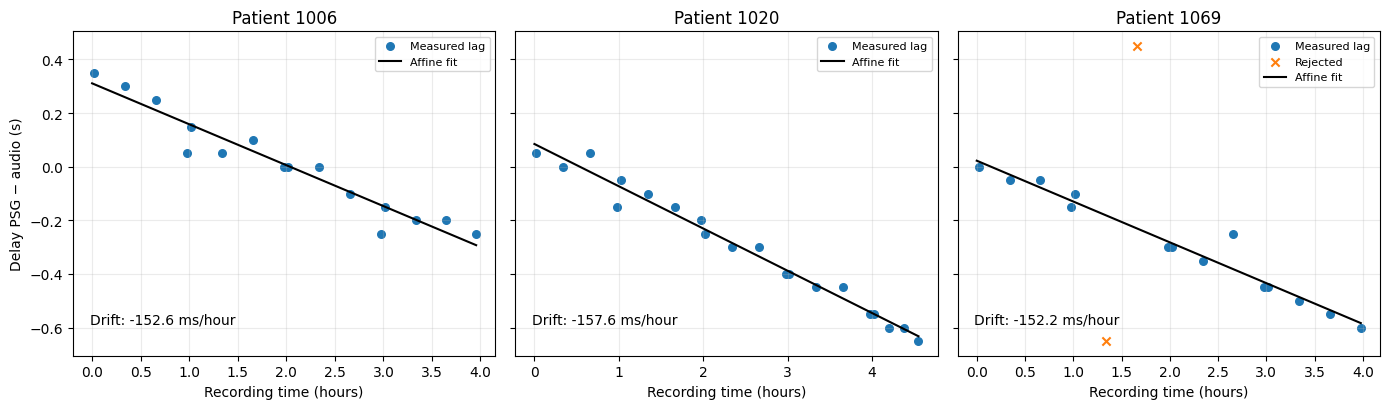

In [14]:
patients = ("1006", "1020", "1069")
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)

for ax, patient in zip(axes, patients):
    fit = json.loads((DATA / "alignment" / patient / f"{patient}.json").read_text())
    points = np.array(fit["points"])
    good = np.array(fit["inlier_mask"], dtype=bool)
    time, lag = points[:, 0], points[:, 1]

    ax.scatter(time[good] / 3600, lag[good], s=30, label="Measured lag")
    if (~good).any():
        ax.scatter(time[~good] / 3600, lag[~good], s=35,
                   marker="x", color="tab:orange", label="Rejected")
    line = np.array([0, time.max()])
    ax.plot(line / 3600, (fit["a"] - 1) * line + fit["b"],
            color="black", linewidth=1.5, label="Affine fit")
    ax.set_title(f"Patient {patient}")
    ax.set_xlabel("Recording time (hours)")
    ax.grid(alpha=0.25)
    ax.text(0.04, 0.1, f"Drift: {(fit['a'] - 1) * 3600000:.1f} ms/hour",
            transform=ax.transAxes, fontsize=10)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Delay PSG − audio (s)")
fig.tight_layout()
fig.savefig(FIGURES / "alignment_lag.png", dpi=200)
plt.show()


In [15]:

WINDOW, CONTEXT = 60, 600 #s
STFT_WINDOW, STFT_HOP = 40, 10 #ms
MEL_BANDS = 128 
N_FFT = round(STFT_WINDOW * 48000 / 1000)
HOP = round(STFT_HOP * 48000 / 1000)

PATIENT, START, DURATION = "1010", 1100, 60
path = DATA / "audio" / PATIENT / f"{PATIENT}[001].wav"

with sf.SoundFile(path) as f:
    assert f.samplerate == 48000
    f.seek(int(START * 48000))
    audio = f.read(int(DURATION * 48000), dtype="float32")


hann = torch.hann_window(N_FFT, device=DEVICE)
mel_filters = melscale_fbanks(N_FFT // 2 + 1, 0, 24000, MEL_BANDS, 48000, norm="slaney", mel_scale="slaney").T.to(DEVICE)

with torch.inference_mode():
    audio = torch.as_tensor(audio, dtype=torch.float32, device=DEVICE)
    spec = torch.stft(audio, n_fft=N_FFT, hop_length=HOP, window=hann, 
                            center=True, pad_mode="reflect", return_complex=True).abs()[:, :-1]
    mel_spec = (mel_filters @ spec)
    a = torch.tensor([1, -0.975], dtype=torch.float32, device=DEVICE)
    b = torch.tensor([0.025, 0], dtype=torch.float32, device=DEVICE)
    smooth = lfilter(mel_spec, a, b, clamp=False)
    decay = (0.975 ** torch.arange(1, DURATION*100+1, dtype=torch.float64, device=DEVICE)).float()
    smooth += mel_spec[:, :1] * decay
    pcen_spec = torch.sqrt(mel_spec / (1e-6 + smooth).pow(0.98) + 2) - np.sqrt(2)

    spec= spec.cpu().numpy()
    mel_spec= mel_spec.cpu().numpy()
    pcen_spec = pcen_spec.cpu().numpy()

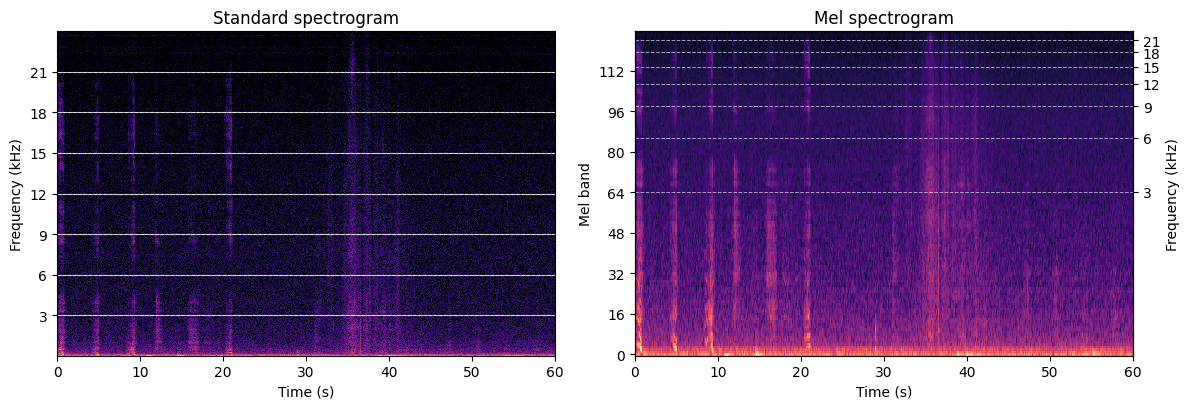

In [16]:

def log_mag(values):
    return 20 * np.log10(np.maximum(values / max(values.max(), 1e-12), 1e-4))

def hz_to_mel(f):
    return np.where(f < 1000, f / (200 / 3), 15 + np.log(np.maximum(f, 1) / 1000) / (np.log(6.4) / 27))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
axes[0].imshow(log_mag(spec), origin="lower", aspect="auto",
            extent=[0, DURATION, 0, 24000],
            cmap="magma", interpolation="nearest")
axes[0].grid(axis="y")
axes[1].imshow(log_mag(mel_spec), origin="lower", aspect="auto",
            extent=[0, DURATION, -0.5, MEL_BANDS - 0.5],
            cmap="magma", interpolation="nearest")

freqs = np.arange(3000, 24000, 3000)
mel_y = (MEL_BANDS + 1) * hz_to_mel(freqs) / hz_to_mel(24000) - 1
bands = np.arange(0, MEL_BANDS, 16)

for f, y in zip(freqs, mel_y):
    axes[0].axhline(f, color="white", alpha=0.6, linestyle="--", linewidth=0.7)
    axes[1].axhline(y, color="white", alpha=0.6, linestyle="--", linewidth=0.7)

axes[0].set_title("Standard spectrogram")
axes[0].set_yticks(freqs, [f"{f/1000:g}" for f in freqs])
axes[0].set_ylabel("Frequency (kHz)")
axes[0].set_xlabel("Time (s)")
axes[1].set_title("Mel spectrogram")
axes[1].set_yticks(np.arange(0, MEL_BANDS, 16))
axes[1].set_ylabel("Mel band")
axes[1].set_xlabel("Time (s)")
ax_freq = axes[1].twinx()
ax_freq.set_ylim(axes[1].get_ylim())
ax_freq.set_yticks(mel_y, [f"{f/1000:g}" for f in freqs])
ax_freq.set_ylabel("Frequency (kHz)")

fig.tight_layout()
plt.savefig(FIGURES / "mel_comparison.png")
plt.show()

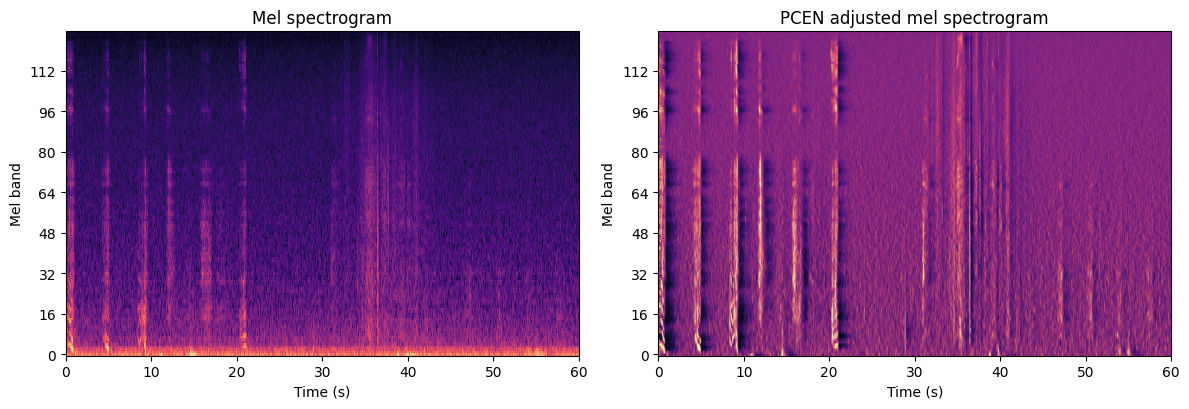

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
axes[0].imshow(log_mag(mel_spec), origin="lower", aspect="auto",
            extent=[0, DURATION, -0.5, MEL_BANDS - 0.5],
            cmap="magma", interpolation="nearest")
im = axes[1].imshow(pcen_spec, origin="lower", aspect="auto",
    extent=[0, DURATION, -0.5, MEL_BANDS - 0.5],
    cmap="magma", vmin=0, vmax=np.quantile(pcen_spec, 0.995))

bands = np.arange(0, MEL_BANDS, 16)
axes[0].set_title("Mel spectrogram")
axes[0].set_yticks(np.arange(0, MEL_BANDS, 16))
axes[0].set_ylabel("Mel band")
axes[0].set_xlabel("Time (s)")
axes[1].set_title("PCEN adjusted mel spectrogram")
axes[1].set_yticks(np.arange(0, MEL_BANDS, 16))
axes[1].set_ylabel("Mel band")
axes[1].set_xlabel("Time (s)")

fig.tight_layout()
plt.savefig(FIGURES / "pcen_comparison.png")
plt.show()

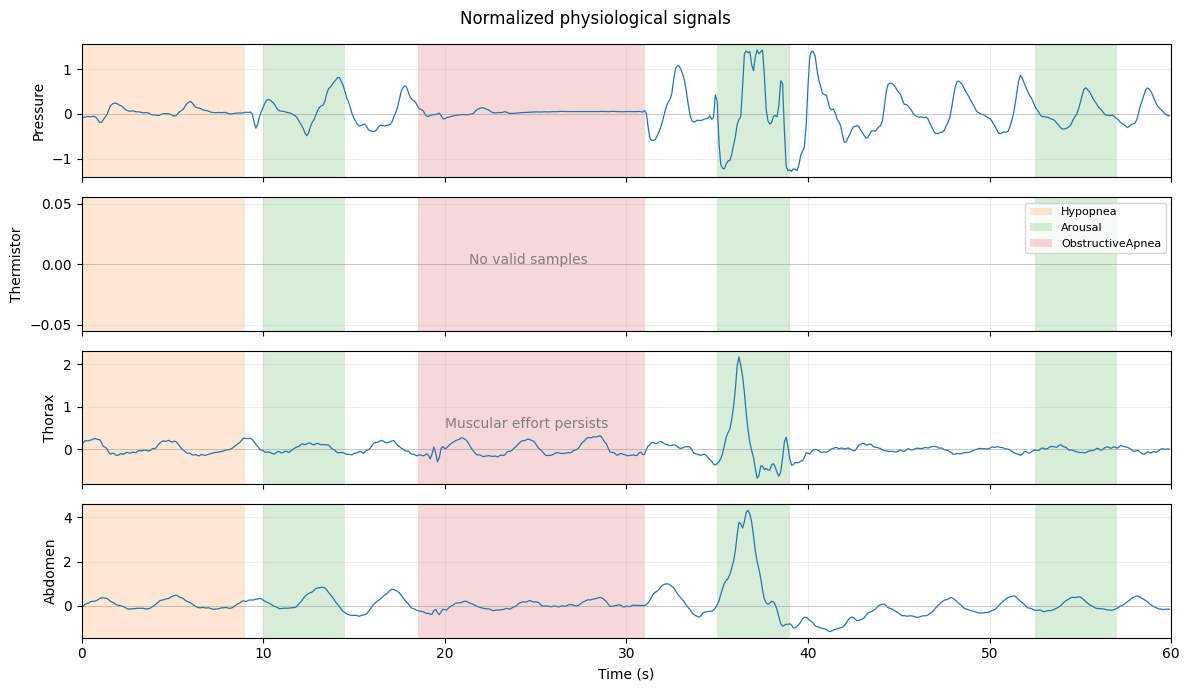

In [29]:
# Load only the preprocessing definitions and parameters, not the generation loop.
path = Path("2_preprocessing.ipynb")
if not path.exists():
    path = Path("final/2_preprocessing.ipynb")
preprocessing = json.loads(path.read_text())
prepare = {}
functions = {"load_signals", "load_masks", "correct_pressure_polarity",
             "normalize_targets", "prepare_signals"}
parameters = {"DATA", "names", "labels", "WINDOW", "CONTEXT"}
for cell in preprocessing["cells"]:
    if cell["cell_type"] != "code":
        continue
    for node in ast.parse("".join(cell["source"])).body:
        if (isinstance(node, (ast.Import, ast.ImportFrom))
            or isinstance(node, ast.FunctionDef) and node.name in functions
            or isinstance(node, ast.Assign) and any(
                isinstance(item, ast.Name) and item.id in parameters
                for target in node.targets for item in ast.walk(target))):
            exec(compile(ast.Module(body=[node], type_ignores=[]), str(path), "exec"), prepare)

prepare["DATA"] = DATA
signals, valid = prepare["prepare_signals"](PATIENT)
a, b = round(START * 10), round((START + DURATION) * 10)
assert 0 <= a < b <= len(signals), "Window outside physiological recording"
time = np.arange(b - a) / 10

fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for c, (ax, name) in enumerate(zip(axes, ["Pressure", "Thermistor", "Thorax", "Abdomen"])):
    ax.plot(time, np.where(valid[a:b, c], signals[a:b, c], np.nan), linewidth=0.9)
    if not valid[a:b, c].any():
        ax.text(0.41, 0.5, "No valid samples",
                transform=ax.transAxes, ha="center", color="gray")
    ax.axhline(0, color="gray", linewidth=0.5, alpha=0.5)
    ax.set_ylabel(name)
    ax.grid(alpha=0.2)

colors = {"ObstructiveApnea": "tab:red", "CentralApnea": "tab:blue",
          "MixedApnea": "tab:purple", "Hypopnea": "tab:orange", "Arousal": "tab:green"}
root = prepare["ET"].parse(DATA / "annotations" / f"{PATIENT}.rml").getroot()
for event in root.iter():
    kind = event.get("Type", "")
    if kind not in colors:
        continue
    start = float(event.get("Start"))
    end = start + float(event.get("Duration"))
    if start < START + DURATION and end > START:
        for ax in axes:
            ax.axvspan(max(start, START) - START, min(end, START + DURATION) - START,
                       color=colors[kind], alpha=0.18, linewidth=0, label=kind)

handles, labels = axes[0].get_legend_handles_labels()
legend = dict(zip(labels, handles))
if legend:
    axes[1].legend(legend.values(), legend.keys(), loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, DURATION)

axes[2].text(20, 0.5, "Muscular effort persists", color="gray")

fig.suptitle(f"Normalized physiological signals")
fig.tight_layout()
fig.savefig(FIGURES / "physiological_signals.png", dpi=200)
plt.show()
